In [3]:

import os
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount("/content/drive")

PROJECT = "/content/drive/MyDrive/simuteh-2330511089-"
SRC = os.path.join(PROJECT, "src")
DATA = os.path.join(PROJECT, "data", "sintetis")
HASIL = os.path.join(PROJECT, "hasil")

os.makedirs(HASIL, exist_ok=True)
sys.path.insert(0, SRC)

sys.modules.pop("utils_cv", None)
sys.modules.pop("praproses", None)

from utils_cv import baca, kontras_bercak
from praproses import praproses, simpan_param

label = pd.read_csv(os.path.join(DATA, "label.csv"))

# Parameter awal untuk diuji, bukan klaim bahwa ini sudah paling optimal.
param = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0
}

# Pilih kanal berdasarkan hasil Bagian 2.
# 0 = B, 1 = G, 2 = R. Ganti bila hasil eksperimenmu menunjukkan kanal lain lebih baik.
KANAL = 2

simpan_param(
    param,
    os.path.join(HASIL, "param_praproses.json")
)

print("Parameter tersimpan:")
print(param)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Parameter tersimpan:
{'lebar': 640, 'gamma': 1.0, 'clahe_clip': 2.0, 'clahe_tile': 8, 'penapis': 'median', 'kernel': 3, 'sigma': 1.0, 'tajam_k': 0.0}


,kondisi,KB_sebelum,KB_sesudah,perubahan_persen
0,bayangan,4.93,8.34,71.58
1,gelap,8.40,14.70,74.93
2,kontras_rendah,3.69,5.11,46.53
3,normal,8.00,9.83,24.91
4,terang,6.17,6.44,4.98


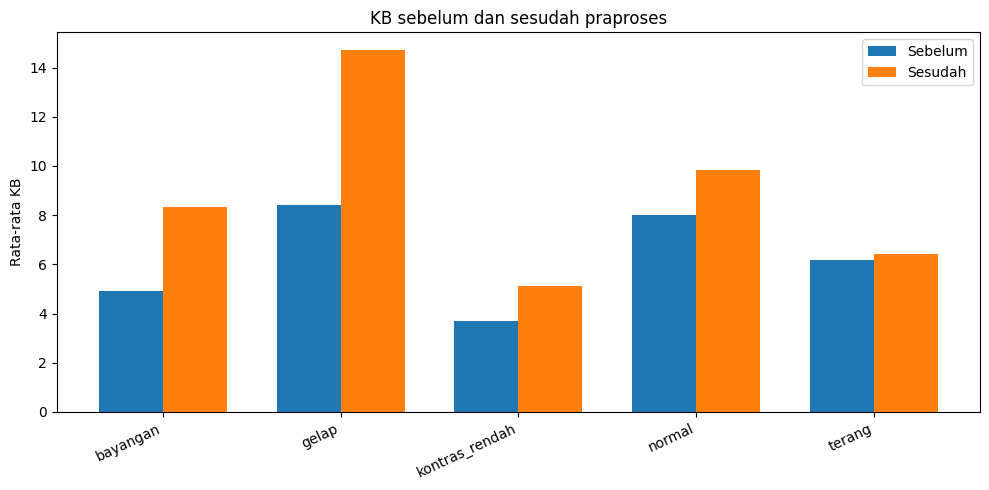

In [4]:

def baca_mask(nama, jenis, ukuran=None):
    path = os.path.join(DATA, jenis, nama)
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if mask is None:
        raise FileNotFoundError(f"Mask tidak ditemukan: {path}")

    if ukuran is not None and (mask.shape[1], mask.shape[0]) != ukuran:
        mask = cv2.resize(
            mask, ukuran,
            interpolation=cv2.INTER_NEAREST
        )

    return mask


baris = []

for _, d in label[label["kelas"] != "sehat"].iterrows():
    nama = d["nama_file"]

    img = baca(os.path.join(DATA, "citra", nama))
    out = praproses(img, param)

    md_asli = baca_mask(nama, "mask_daun")
    mb_asli = baca_mask(nama, "mask_bercak")

    # KB sebelum menggunakan citra dan mask pada ukuran aslinya
    kb_sebelum = kontras_bercak(
        img[:, :, KANAL], md_asli, mb_asli
    )

    # Sesuaikan mask dengan ukuran keluaran praproses
    ukuran_out = (out.shape[1], out.shape[0])
    md_out = baca_mask(nama, "mask_daun", ukuran_out)
    mb_out = baca_mask(nama, "mask_bercak", ukuran_out)

    kb_sesudah = kontras_bercak(
        out[:, :, KANAL], md_out, mb_out
    )

    baris.append([
        nama, d["kelas"], d["kondisi_cahaya"],
        kb_sebelum, kb_sesudah
    ])

evaluasi = pd.DataFrame(
    baris,
    columns=[
        "nama_file", "kelas", "kondisi",
        "KB_sebelum", "KB_sesudah"
    ]
)

evaluasi["perubahan_persen"] = (
    (evaluasi["KB_sesudah"] - evaluasi["KB_sebelum"])
    / evaluasi["KB_sebelum"].replace(0, np.nan)
    * 100
)

tabel12 = evaluasi.groupby("kondisi", as_index=False).agg(
    KB_sebelum=("KB_sebelum", "mean"),
    KB_sesudah=("KB_sesudah", "mean"),
    perubahan_persen=("perubahan_persen", "mean")
).round(2)

display(tabel12)

evaluasi.to_csv(
    os.path.join(HASIL, "b5_evaluasi_40_citra.csv"),
    index=False
)
tabel12.to_csv(
    os.path.join(HASIL, "b5_tabel12.csv"),
    index=False
)

plt.figure(figsize=(10, 5))
x = np.arange(len(tabel12))
lebar_bar = 0.36

plt.bar(
    x - lebar_bar/2, tabel12["KB_sebelum"],
    lebar_bar, label="Sebelum"
)
plt.bar(
    x + lebar_bar/2, tabel12["KB_sesudah"],
    lebar_bar, label="Sesudah"
)
plt.xticks(x, tabel12["kondisi"], rotation=25, ha="right")
plt.ylabel("Rata-rata KB")
plt.title("KB sebelum dan sesudah praproses")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(HASIL, "b5_grafik_kb.png"),
    dpi=150
)
plt.show()


In [5]:

baris_sehat = []

for _, d in label[label["kelas"] == "sehat"].iterrows():
    nama = d["nama_file"]

    img = baca(os.path.join(DATA, "citra", nama))
    out = praproses(img, param)

    md = baca_mask(nama, "mask_daun")
    md_out = baca_mask(
        nama, "mask_daun",
        (out.shape[1], out.shape[0])
    )

    kanal_sebelum = img[:, :, KANAL].astype(float)
    kanal_sesudah = out[:, :, KANAL].astype(float)

    std_sebelum = kanal_sebelum[md > 0].std()
    std_sesudah = kanal_sesudah[md_out > 0].std()

    baris_sehat.append([
        nama, d["kondisi_cahaya"],
        std_sebelum, std_sesudah
    ])

tabel_sehat = pd.DataFrame(
    baris_sehat,
    columns=["nama_file", "kondisi", "std_sebelum", "std_sesudah"]
)

tabel_sehat["perubahan_std_persen"] = (
    (tabel_sehat["std_sesudah"] - tabel_sehat["std_sebelum"])
    / tabel_sehat["std_sebelum"].replace(0, np.nan)
    * 100
)

ringkasan_sehat = tabel_sehat.groupby("kondisi", as_index=False).agg(
    std_sebelum=("std_sebelum", "mean"),
    std_sesudah=("std_sesudah", "mean"),
    perubahan_std_persen=("perubahan_std_persen", "mean")
).round(2)

display(ringkasan_sehat)

tabel_sehat.to_csv(
    os.path.join(HASIL, "b5_uji_bercak_palsu.csv"),
    index=False
)
ringkasan_sehat.to_csv(
    os.path.join(HASIL, "b5_ringkasan_bercak_palsu.csv"),
    index=False
)

# Ambil satu citra sehat untuk setiap kondisi cahaya
kondisi_target = [
    "normal", "gelap", "terang",
    "kontras_rendah", "bayangan"
]

fig, axes = plt.subplots(5, 2, figsize=(10, 20))

for i, kondisi in enumerate(kondisi_target):
    baris_kondisi = label[
        (label["kelas"] == "sehat") &
        (label["kondisi_cahaya"] == kondisi)
    ]

    if baris_kondisi.empty:
        axes[i, 0].set_title(f"{kondisi}: data tidak ditemukan")
        axes[i, 1].set_title(f"{kondisi}: data tidak ditemukan")
        axes[i, 0].axis("off")
        axes[i, 1].axis("off")
        continue

    nama = baris_kondisi.iloc[0]["nama_file"]
    img = baca(os.path.join(DATA, "citra", nama))
    out = praproses(img, param)

    axes[i, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{kondisi} - sebelum ({nama})")

    axes[i, 1].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title(f"{kondisi} - sesudah")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.savefig(
    os.path.join(HASIL, "b5_panel_citra_sehat.png"),
    dpi=150
)
plt.show()


Output hidden; open in https://colab.research.google.com to view.

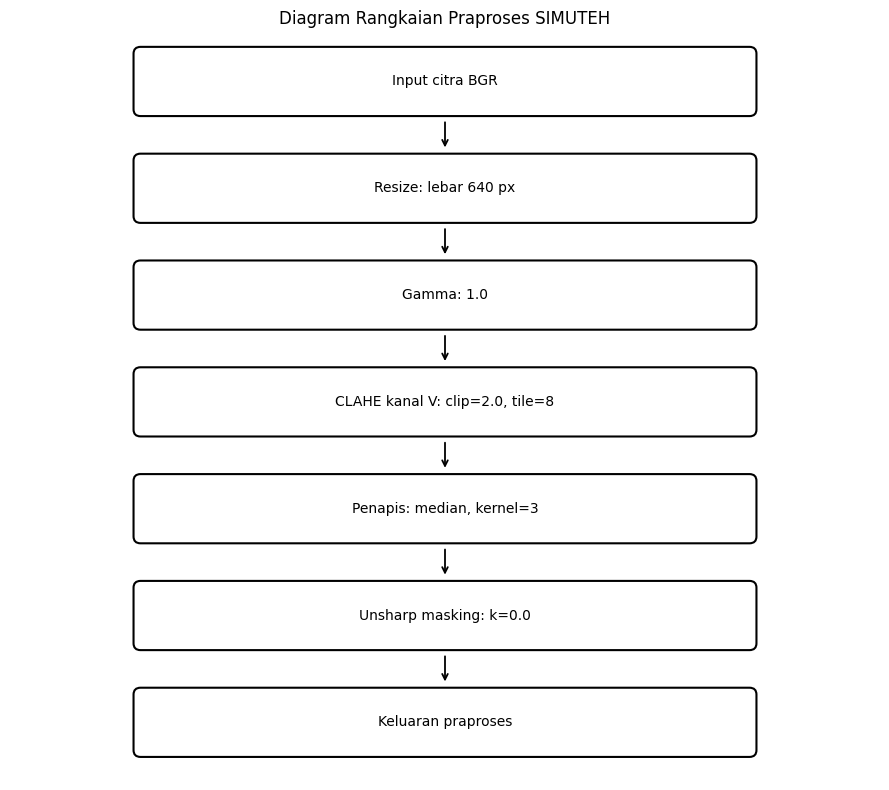

In [6]:

from matplotlib.patches import FancyBboxPatch

langkah = [
    f"Input citra BGR",
    f"Resize: lebar {param['lebar']} px",
    f"Gamma: {param['gamma']}",
    f"CLAHE kanal V: clip={param['clahe_clip']}, tile={param['clahe_tile']}",
    f"Penapis: {param['penapis']}, kernel={param['kernel']}",
    f"Unsharp masking: k={param['tajam_k']}",
    "Keluaran praproses"
]

fig, ax = plt.subplots(figsize=(9, 8))
ax.set_xlim(0, 10)
ax.set_ylim(0, len(langkah) * 1.25)
ax.axis("off")

for i, teks in enumerate(langkah):
    y = len(langkah) * 1.25 - i * 1.25 - 0.9
    kotak = FancyBboxPatch(
        (1.5, y), 7, 0.65,
        boxstyle="round,pad=0.08",
        fill=False, linewidth=1.5
    )
    ax.add_patch(kotak)
    ax.text(5, y + 0.325, teks, ha="center", va="center", fontsize=10)

    if i < len(langkah) - 1:
        ax.annotate(
            "", xy=(5, y - 0.48), xytext=(5, y - 0.12),
            arrowprops=dict(arrowstyle="->", linewidth=1.3)
        )

plt.title("Diagram Rangkaian Praproses SIMUTEH")
plt.tight_layout()
plt.savefig(
    os.path.join(HASIL, "b5_diagram_praproses.png"),
    dpi=150
)
plt.show()


In [7]:
import json

path_param = os.path.join(HASIL, "param_praproses.json")

with open(path_param, "r", encoding="utf-8") as f:
    print(json.dumps(json.load(f), indent=2))

{
  "lebar": 640,
  "gamma": 1.0,
  "clahe_clip": 2.0,
  "clahe_tile": 8,
  "penapis": "median",
  "kernel": 3,
  "sigma": 1.0,
  "tajam_k": 0.0
}
